# 10. Modelos y benchmark de demanda

El benchmark compara MLP, LSTM y CNN1D como tres familias de Deep Learning, acompañadas por una regresión ARX penalizada y dos referencias estacionales. Las configuraciones se seleccionaron por MASE de validación; la evaluación final conserva 195 inicializaciones por familia sobre los mismos días de prueba. El análisis procede de la ejecución GPU v2 publicada el 8 de noviembre de 2026.

In [1]:
from pathlib import Path
import json,hashlib,itertools
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/processed/panel_horario.parquet').exists())
SHA='02ff447d94fa78e1cde323fa2382da5bce24fb6e'
SNAP=ROOT/'results/repositorio'/SHA
R=SNAP/'results/base_v2'; OUT=ROOT/'results/jbook/modelos'; OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
plan=json.loads((R/'plan_gpu.json').read_text(encoding='utf-8'))
analisis=json.loads((OUT/'plan_analisis_secundario.json').read_text(encoding='utf-8'))
registro_archivos=json.loads((R/'resultados_guardados.json').read_text(encoding='utf-8'))['archivos']
for nombre,huella in analisis['sha256'].items():
    assert hashlib.sha256((R/nombre).read_bytes()).hexdigest()==huella
verificados=[]
for nombre,huella in plan['sha256'].items():
    p=SNAP/nombre if (SNAP/nombre).exists() else ROOT/nombre
    contenido=p.read_bytes()
    # El panel binario coincide exactamente; los textos locales pueden tener CRLF.
    coincide=hashlib.sha256(contenido).hexdigest()==huella
    if not coincide and p.suffix in ['.json','.md','.py']:
        coincide=hashlib.sha256(contenido.replace(b'\r\n',b'\n')).hexdigest()==huella
    assert coincide,nombre
    verificados.append(nombre)
for nombre,info in registro_archivos.items():
    if (R/nombre).is_file():
        assert hashlib.sha256((R/nombre).read_bytes()).hexdigest()==info['sha256'],nombre
runs=pd.read_csv(R/'final_runs.csv'); piloto=pd.read_csv(R/'piloto.csv')
busqueda=pd.read_csv(R/'busqueda.csv'); ajustes=pd.read_csv(R/'resumen_ajustes.csv')
mejores=json.loads((R/'mejor_config.json').read_text(encoding='utf-8'))
referencias=json.loads((R/'referencias_test.json').read_text(encoding='utf-8'))
ref_cv=json.loads((R/'referencias_cv.json').read_text(encoding='utf-8'))
env=json.loads((R/'entorno_final.json').read_text(encoding='utf-8'))
escala_mase=env['escala_mase']
neuronales=['mlp','lstm','cnn1d']; modelos=['mlp','arx_lineal','lstm','cnn1d']
etiquetas={'mlp':'MLP','arx_lineal':'ARX','lstm':'LSTM','cnn1d':'CNN1D','ingenuo_24h':'Ingenuo diario','ingenuo_168h':'Ingenuo semanal'}
assert not runs.duplicated(['modelo','semilla']).any()
assert set(runs.modelo)==set(modelos)
for nombre,d in runs.groupby('modelo'):
    assert set(d.semilla)==set(range(1000,1195))
    assert d.params.map(json.loads).map(lambda p:p==mejores[nombre]['params']).all()
assert np.isfinite(runs[['MASE','RMSE','MAE','MASE_h1','MASE_h12','MASE_h24']]).all().all()
assert np.allclose(runs.MAE/runs.MASE,escala_mase)
publicado=pd.read_csv(R/'resumen_final.csv').set_index('modelo')
for nombre,d in runs.groupby('modelo'):
    for metrica in ['MASE','RMSE','MAE','sMAPE','MAPE','MASE_h1','MASE_h12','MASE_h24']:
        assert np.isclose(d[metrica].mean(),publicado.loc[nombre,metrica+'_media'])
n_ajustes=len(ajustes); n_fuentes=len(verificados)


# Demanda observada archivada en un pliegue de 2021 y en la prueba final.
indice_ref=pd.read_csv(R/'indice_artefactos.csv')
sel_2021=(indice_ref.etapa=='piloto')&(indice_ref.modelo=='mlp')&(indice_ref.semilla==100)&indice_ref.inicio_evaluacion.str.startswith('2021')&indice_ref.archivo.str.endswith('/predicciones.npz')
sel_test=(indice_ref.etapa=='final')&(indice_ref.modelo=='mlp')&(indice_ref.semilla==1000)&indice_ref.archivo.str.endswith('/predicciones.npz')
assert sel_2021.sum()==1 and sel_test.sum()==1
series=[]
for sel in [sel_2021,sel_test]:
    with np.load(R/indice_ref.loc[sel,'archivo'].iloc[0],allow_pickle=False) as z:
        origen_ref=pd.to_datetime(z['origen'],unit='ns',utc=True).tz_convert('America/Bogota')
        idx=pd.DatetimeIndex([o+pd.Timedelta(hours=h) for o in origen_ref for h in range(24)])
        series.append(pd.Series(z['y'].ravel(),index=idx))
        if sel is sel_test:
            y_ref=z['y'].copy();orig_ref=z['origen'].copy();fechas_ref=origen_ref
observado=pd.concat(series).sort_index()
assert observado.index.is_unique
ref_pred={}
lag_publicacion=1
for nombre,base in [('ingenuo_24h',24),('ingenuo_168h',168)]:
    p=np.empty_like(y_ref)
    for h in range(24):
        k=max(1,int(np.ceil((h+1+lag_publicacion)/base))) if base==24 else 1
        requeridas=fechas_ref+pd.Timedelta(hours=h-base*k)
        p[:,h]=observado.loc[requeridas].to_numpy()
    ref_pred[nombre]=p
# El último intervalo disponible al origen es el que empieza dos horas antes.
ref_pred['persistencia']=np.repeat(observado.loc[fechas_ref-pd.Timedelta(hours=2)].to_numpy()[:,None],24,axis=1)
for nombre,p in ref_pred.items():
    absoluto=np.abs(p-y_ref);e=p-y_ref
    res={'MAE':float(absoluto.mean()),'RMSE':float(np.sqrt(np.mean(e*e))),
         'MASE':float(absoluto.mean()/escala_mase),
         'sMAPE':float(np.mean(200*absoluto/(np.abs(p)+np.abs(y_ref)))),
         'MAPE':float(np.mean(100*absoluto/np.abs(y_ref))),
         'R2':float(1-np.mean(e*e)/np.var(y_ref))}
    for h in [1,12,24]:res[f'MASE_h{h}']=float(absoluto[:,h-1].mean()/escala_mase)
    if nombre in referencias:
        for metrica,valor in referencias[nombre].items():
            assert np.isclose(res[metrica],valor,rtol=1e-10),(nombre,metrica)
    referencias[nombre]=res
etiquetas['persistencia']='Persistencia disponible'
np.savez_compressed(OUT/'referencias_desde_observaciones.npz',y=y_ref,origen=orig_ref,**ref_pred)
(OUT/'referencias_reconstruidas.json').write_text(json.dumps(referencias,indent=2),encoding='utf-8')


Out[0]: 951


Se verifican 9 fuentes y archivos del plan y 1640 ajustes resumidos. La escala semanal de MASE es 215,617.90 kWh, calculada en 2000–2017. Las medias publicadas se reconstruyen desde los registros individuales; no se ejecutan ajustes ni nuevas predicciones.

Las referencias deterministas se reconstruyen con demanda observada ya archivada: persistencia del último intervalo disponible e ingenuos diario y semanal. Se respeta el rezago de publicación de una hora. Los resultados de los dos ingenuos coinciden con los publicados; no se ejecutan redes ni se ajustan parámetros.

## 10.1 Entradas, particiones y ejecución

Cada origen diario de las 00:00 produce 24 demandas horarias mediante salida directa. La historia contiene 168 filas anteriores al origen. Las entradas son demanda real y calendario: el calendario histórico se concatena a las secuencias LSTM/CNN y el calendario futuro conocido alimenta una rama separada. MLP y ARX utilizan demanda histórica y calendario del horizonte aplanados.

La demanda se divide por su nivel medio histórico y se devuelve a kWh al evaluar. El estandarizador inicial de calendario se fija con 2000–2017; MLP y ARX ajustan además su estandarización tabular con el tramo de optimización de cada pliegue. El escalado inicial incluye parte de la reserva interna de parada del primer pliegue, por lo que no representa una separación estricta de todas las transformaciones respecto de esa reserva. No utiliza el año externo ni la prueba.

La selección aplica cuatro años externos, 2018–2021, y reserva el último 10 % del historial previo para parada temprana. El ajuste final emplea el historial anterior a 2022 con la misma separación interna; la prueba comprende 2022–2025. Las ejecuciones usan Linux, Python 3.12.3, PyTorch 2.9.1 con ROCm 6.4 y GPU AMD de aproximadamente 12 GB, con determinismo estricto y sin precisión mixta.

## 10.2 Arquitecturas y complejidad

**MLP.** Para la ventana aplanada $\mathbf z$ y el calendario futuro $\mathbf k$, la salida es

$$\widehat{\mathbf y}=W_o\,\phi(W_2\,\phi(W_1[\mathbf z;\mathbf k]+\mathbf b_1)+\mathbf b_2)+\mathbf b_o.$$

La configuración seleccionada tiene dos capas ocultas de 128 unidades, ReLU y dropout. Con dimensión $d$, ancho $u$, $a$ capas y horizonte $H$, el costo dominante por origen es $O(du+(a-1)u^2+uH)$.

**LSTM.** Una capa de 256 unidades procesa la historia. Sus compuertas actualizan memoria y estado oculto:

$$\mathbf c_t=\mathbf f_t\odot\mathbf c_{t-1}+\mathbf i_t\odot\mathbf g_t,\qquad
\mathbf h_t=\mathbf o_t\odot\tanh(\mathbf c_t).$$

El estado final se concatena con una proyección del calendario futuro y una cabeza densa genera las 24 salidas. El costo recurrente es $O(Lu(f+u))$, más las proyecciones densas. El dropout seleccionado afecta las salidas y la cabeza; al haber una sola capa recurrente, no se aplica dropout entre capas LSTM.

**CNN1D.** Un bloque de 32 filtros, kernel 7, ReLU y Dropout1d transforma exclusivamente la historia:

$$\mathbf z_t=\phi\left(\sum_{j=-3}^{3}W_j\mathbf x_{t+j}+\mathbf b\right).$$

El padding simétrico opera dentro de una historia ya observada. La salida se promedia en siete bloques de 24 horas y se combina con el calendario futuro mediante capas densas. El costo convolucional es $O(Lkfc)$ para un bloque, con kernel $k$, canales $f$ y filtros $c$; se añaden las proyecciones densas.

**ARX de contexto.** Una transformación afín de rezagos y calendario incorpora penalización L1 o L2, con costo $O(dH)$. Implementarla en PyTorch no la convierte en una arquitectura profunda; se reporta fuera de las tres familias neuronales. La penalización L1 se optimiza por gradiente y no garantiza coeficientes exactamente nulos.

In [2]:
configuraciones=[]
for nombre in modelos:
    p=mejores[nombre]['params']
    configuraciones.append({'Modelo':etiquetas[nombre],
        'Estructura':('2 × 128' if nombre=='mlp' else '1 × 256' if nombre=='lstm' else '1 × 32; kernel 7' if nombre=='cnn1d' else '168 rezagos; L1'),
        'Parámetros':int(runs.loc[runs.modelo==nombre,'n_parametros'].iloc[0]),
        'Dropout':p.get('dropout',0.),'LR':p['lr'],'Lote':p['batch_size'],
        'Planificador':p['scheduler'],'Pérdida':p['perdida'],'Paciencia':p['paciencia'],
        'Decaimiento':p.get('weight_decay',0.)})
display(pd.DataFrame(configuraciones).set_index('Modelo').style.format({'Dropout':'{:.4f}','LR':'{:.3g}','Decaimiento':'{:.3g}'}))


,Estructura,Parámetros,Dropout,LR,Lote,Planificador,Pérdida,Paciencia,Decaimiento
Modelo,,,,,,,,,
MLP,2 × 128,111896,0.0035,0.00469,64,plateau,huber,8,0.000383
ARX,168 rezagos; L1,17304,0.0000,0.000457,256,cosine,mae,25,0
LSTM,1 × 256,567832,0.2046,0.00321,32,none,huber,15,0.000158
CNN1D,1 × 32; kernel 7,33176,0.1402,0.00838,32,plateau,mse,25,8.72e-05


El optimizador común es AdamW, con recorte de norma del gradiente a 1, máximo de 200 épocas y mejora mínima de 10⁻⁶. Se restaura el estado que mejora la pérdida interna por encima de ese umbral. Huber utiliza transición 0,05 en la escala normalizada por nivel; la función de selección externa sigue siendo MASE, independientemente de la pérdida de entrenamiento.

## 10.3 Búsqueda y presupuesto ejecutado

La búsqueda aleatoria utiliza tres semillas por candidato y cuatro pliegues. La adenda de costo computacional redujo LSTM de veinte a cinco configuraciones durante la búsqueda. MLP, CNN1D y ARX conservaron veinte. Esta desigualdad limita la comparación del potencial de las familias; los resultados describen las configuraciones efectivamente exploradas.

etapa,ajustes búsqueda,ajustes finales,ajustes piloto,configuraciones
modelo,,,,
MLP,240,195,20,20
ARX,240,195,20,20
LSTM,60,195,20,5
CNN1D,240,195,20,20


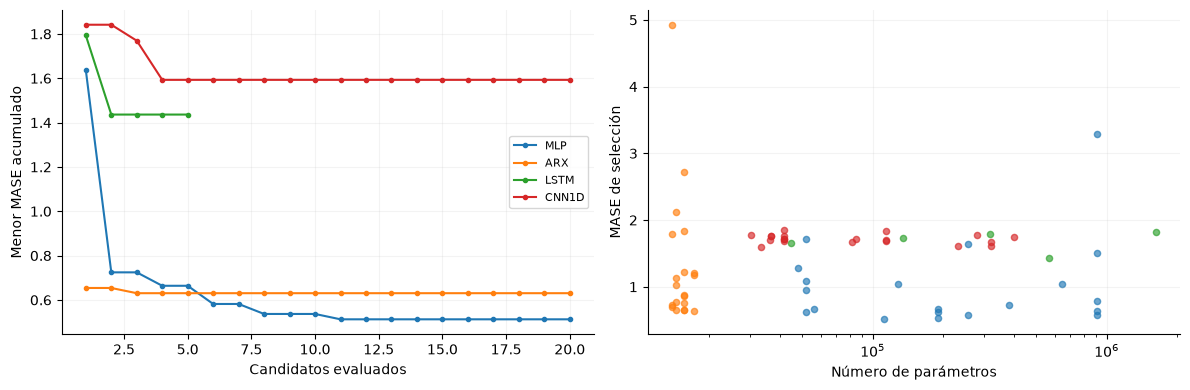

In [3]:
presupuesto=ajustes.groupby(['modelo','etapa']).size().unstack(fill_value=0).reindex(modelos)
presupuesto['configuraciones']=busqueda.groupby('modelo').size()
display(presupuesto.rename(index=etiquetas).rename(columns={'buscar':'ajustes búsqueda','piloto':'ajustes piloto','final':'ajustes finales'}))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for nombre in modelos:
    d=busqueda.loc[busqueda.modelo==nombre].sort_values('config')
    axes[0].plot(np.arange(1,len(d)+1),d.MASE.cummin(),marker='o',ms=3,label=etiquetas[nombre])
    axes[1].scatter(d.n_parametros,d.MASE,label=etiquetas[nombre],s=20,alpha=.65)
axes[0].set(xlabel='Candidatos evaluados',ylabel='Menor MASE acumulado'); axes[0].legend(fontsize=8)
axes[1].set(xscale='log',xlabel='Número de parámetros',ylabel='MASE de selección')
fig.tight_layout(); display(fig); plt.close(fig)
seleccion_mejor=min(neuronales,key=lambda n:mejores[n]['MASE_cv']); cv_mejor=mejores[seleccion_mejor]['MASE_cv']


MLP alcanza el menor MASE de selección entre las redes (0.513). La figura relaciona capacidad y error de los candidatos, sin demostrar que aumentar parámetros produzca una mejora. La curva LSTM termina en el quinto candidato; no equivale al presupuesto de veinte aplicado a las otras familias.

## 10.4 Piloto y dimensionamiento

El piloto utiliza cinco semillas, 100–104, sobre los mismos cuatro pliegues. El dimensionamiento original aplica una aproximación normal de dos muestras y adopta el máximo requerido entre las cuatro familias, con margen relativo del 3 %, α = 0,05 y potencia objetivo 0,80. Se conserva esa decisión y se contrasta con un cálculo pareado retrospectivo.

,Semillas,MASE medio,DE,CV_pct,n_original
modelo,,,,,
MLP,5,0.5211,0.0104,1.9936,7
ARX,5,0.6279,0.0085,1.3490,4
LSTM,5,1.5134,0.1600,10.5696,195
CNN1D,5,1.6041,0.0336,2.0951,8


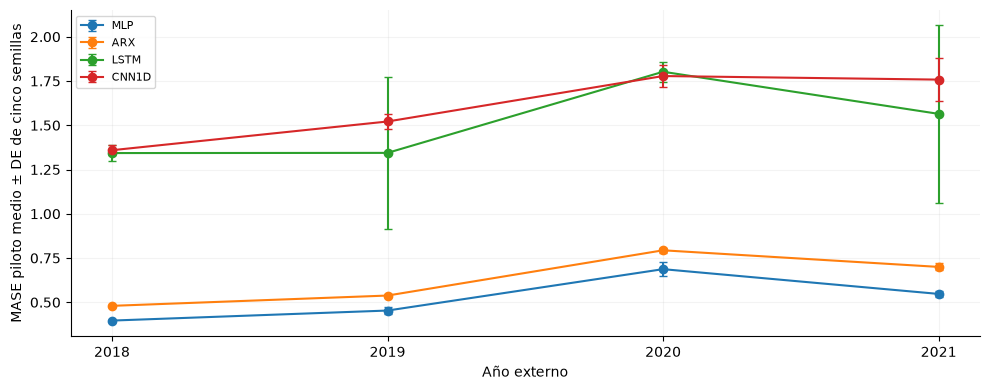

In [4]:
piloto_est=piloto.groupby('modelo').MASE.agg(['count','mean','std']).reindex(modelos)
piloto_est['CV_pct']=100*piloto_est['std']/piloto_est['mean']
zpot=stats.norm.ppf(.975)+stats.norm.ppf(.8)
piloto_est['n_original']=np.ceil(2*(zpot*piloto_est['std']/(.03*piloto_est['mean']))**2).astype(int)
display(piloto_est.rename(index=etiquetas).rename(columns={'count':'Semillas','mean':'MASE medio','std':'DE'}).round(4))
n_final=int(json.loads((R/'piloto_resumen.json').read_text())['n_final'])
assert n_final==195 and piloto_est['n_original'].max()==n_final
fig,ax=plt.subplots()
for nombre in modelos:
    d=piloto[piloto.modelo==nombre]
    medias=[d[f'MASE_{a}'].mean() for a in [2018,2019,2020,2021]]
    desv=[d[f'MASE_{a}'].std(ddof=1) for a in [2018,2019,2020,2021]]
    ax.errorbar([2018,2019,2020,2021],medias,yerr=desv,marker='o',capsize=3,label=etiquetas[nombre])
ax.set(xticks=[2018,2019,2020,2021],xlabel='Año externo',ylabel='MASE piloto medio ± DE de cinco semillas')
ax.legend(fontsize=8);fig.tight_layout();display(fig);plt.close(fig)
cv_lstm=float(piloto_est.loc['lstm','CV_pct'])


LSTM presenta un coeficiente de variación del 10.57 % en el piloto y determina las 195 semillas finales comunes. El cálculo original dimensiona variación de inicialización bajo una aproximación de dos muestras; no estima potencia sobre días ni sustituye el dimensionamiento con diferencias pareadas solicitado por la pauta.

## 10.5 Benchmark de prueba

Las métricas se reconstruyen desde las 780 filas finales. Los intervalos t al 95 % describen variación entre inicializaciones sobre la misma prueba; no son intervalos de muestreo de días. Los tiempos corresponden al ajuste, no a latencia de inferencia.

In [5]:
filas=[]
for nombre in modelos:
    d=runs[runs.modelo==nombre]; n=len(d); media=d.MASE.mean(); sd=d.MASE.std(ddof=1)
    mitad=stats.t.ppf(.975,n-1)*sd/np.sqrt(n)
    filas.append({'Modelo':etiquetas[nombre],'Familia':nombre,'n':n,'MASE':media,'DE':sd,
        'IC95_inf':media-mitad,'IC95_sup':media+mitad,
        'MAE_kWh':d.MAE.mean(),'RMSE_kWh':d.RMSE.mean(),'sMAPE_pct':d.sMAPE.mean(),
        'Ajuste_s_mediana':d.segundos.median(),'Parámetros':d.n_parametros.iloc[0]})
for nombre,v in referencias.items():
    filas.append({'Modelo':etiquetas[nombre],'Familia':nombre,'n':1,'MASE':v['MASE'],
        'MAE_kWh':v['MAE'],'RMSE_kWh':v['RMSE'],'sMAPE_pct':v['sMAPE']})
benchmark=pd.DataFrame(filas).sort_values('MASE').reset_index(drop=True)
benchmark['Orden']=np.arange(1,len(benchmark)+1)
display(benchmark.set_index('Modelo')[['Orden','n','MASE','DE','IC95_inf','IC95_sup','MAE_kWh','RMSE_kWh','sMAPE_pct','Ajuste_s_mediana','Parámetros']].round(4))
benchmark.to_csv(OUT/'benchmark.csv',index=False)
baseline=benchmark.loc[benchmark.Familia=='mlp'].iloc[0]
reduccion_semanal=float(100*(1-baseline.MASE/referencias['ingenuo_168h']['MASE']))
umbral_practico=float(.97*baseline.MASE)


,Orden,n,MASE,DE,IC95_inf,IC95_sup,MAE_kWh,RMSE_kWh,sMAPE_pct,Ajuste_s_mediana,Parámetros
Modelo,,,,,,,,,,,
MLP,1,195,0.6925,0.0345,0.6876,0.6973,149309.3382,1.951019e+05,1.6152,6.81,111896.0
ARX,2,195,0.8313,0.0532,0.8237,0.8388,179235.9995,2.405593e+05,1.9651,3.10,17304.0
Ingenuo semanal,3,1,1.3549,NaN,NaN,NaN,292142.0871,4.446319e+05,3.2140,NaN,NaN
LSTM,4,195,1.7483,0.5161,1.6754,1.8212,376955.3630,4.722413e+05,4.1736,77.07,567832.0
CNN1D,5,195,2.0700,0.0560,2.0621,2.0780,446337.0542,5.584631e+05,4.9417,21.10,33176.0
Ingenuo diario,6,1,2.0767,NaN,NaN,NaN,447778.9936,6.595935e+05,4.9767,NaN,NaN
Persistencia disponible,7,1,4.2340,NaN,NaN,NaN,912916.8841,1.045971e+06,10.0696,NaN,NaN


MLP establece el baseline empírico con MASE 0.692 y MAE 149,309 kWh por intervalo; reduce el error un 48.9 % respecto del ingenuo semanal. LSTM y CNN1D no superan esa referencia. Una reducción práctica del 3 % respecto de MLP corresponde a MASE inferior a 0.672; demostrarla exige además una comparación pareada con incertidumbre adecuada.

## 10.6 Distribución, generalización y costo

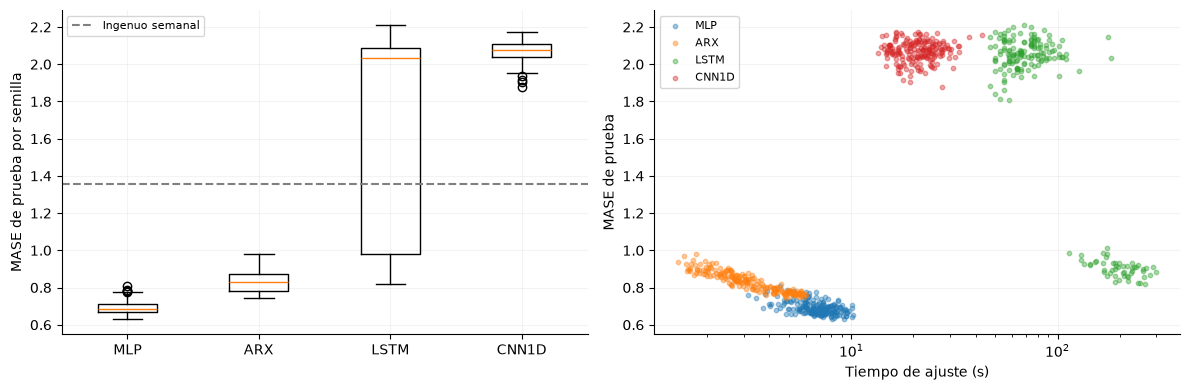

In [6]:
matriz=runs.pivot(index='semilla',columns='modelo',values='MASE').reindex(columns=modelos)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].boxplot([matriz[n] for n in modelos],tick_labels=[etiquetas[n] for n in modelos],showfliers=True)
axes[0].axhline(referencias['ingenuo_168h']['MASE'],ls='--',color='grey',label='Ingenuo semanal')
axes[0].set_ylabel('MASE de prueba por semilla'); axes[0].legend(fontsize=8)
for nombre in modelos:
    d=runs[runs.modelo==nombre]
    axes[1].scatter(d.segundos,d.MASE,label=etiquetas[nombre],s=10,alpha=.4)
axes[1].set(xscale='log',xlabel='Tiempo de ajuste (s)',ylabel='MASE de prueba'); axes[1].legend(fontsize=8)
fig.tight_layout(); display(fig); plt.close(fig)
de_lstm=float(matriz.lstm.std()); de_mlp=float(matriz.mlp.std())


La dispersión entre semillas es mayor en LSTM (DE 0.516) que en MLP (0.034). El diagrama de costo y error permite valorar cada ajuste sin confundir tiempo de entrenamiento con latencia. Las semillas comparten el mismo periodo; su dispersión representa variabilidad algorítmica condicionada a esos datos.

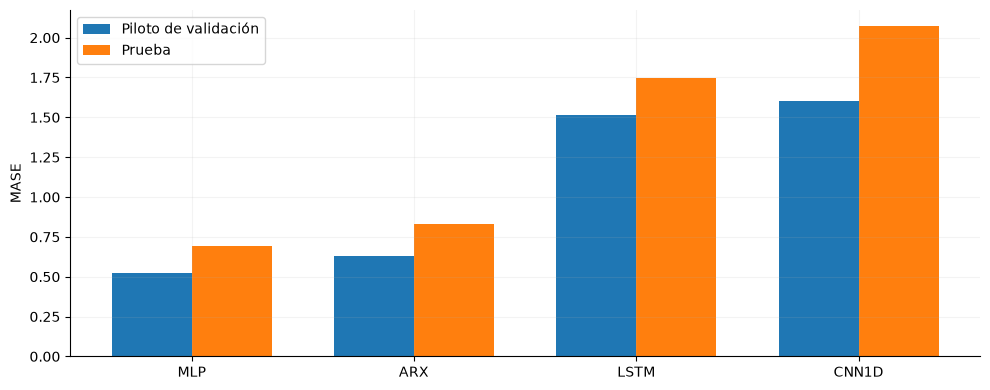

In [7]:
comparacion=pd.read_csv(R/'comparacion_validacion_prueba.csv').set_index('modelo').reindex(modelos)
fig,ax=plt.subplots();pos=np.arange(len(modelos))
ax.bar(pos-.18,comparacion.MASE_validacion_piloto,width=.36,label='Piloto de validación')
ax.bar(pos+.18,comparacion.MASE_prueba,width=.36,label='Prueba')
ax.set(xticks=pos,xticklabels=[etiquetas[n] for n in modelos],ylabel='MASE')
ax.legend();fig.tight_layout();display(fig);plt.close(fig)
brecha_mlp=float(comparacion.loc['mlp','brecha_MASE_pct'])


El MASE de MLP aumenta un 32.9 % entre piloto y prueba. La comparación combina periodos y tamaños de historial distintos; la brecha no identifica por sí sola sobreajuste. El análisis temporal complementario presenta las 24 horas y separa sus errores del cambio global entre periodos.

## 10.7 Parada temprana y pérdidas guardadas

El resumen de ajustes conserva la última pérdida de entrenamiento, la última pérdida interna y su mínimo, junto con épocas totales y época de mínimo reportada. Estos indicadores describen la parada; las curvas completas por época se presentan en el análisis temporal enlazado.

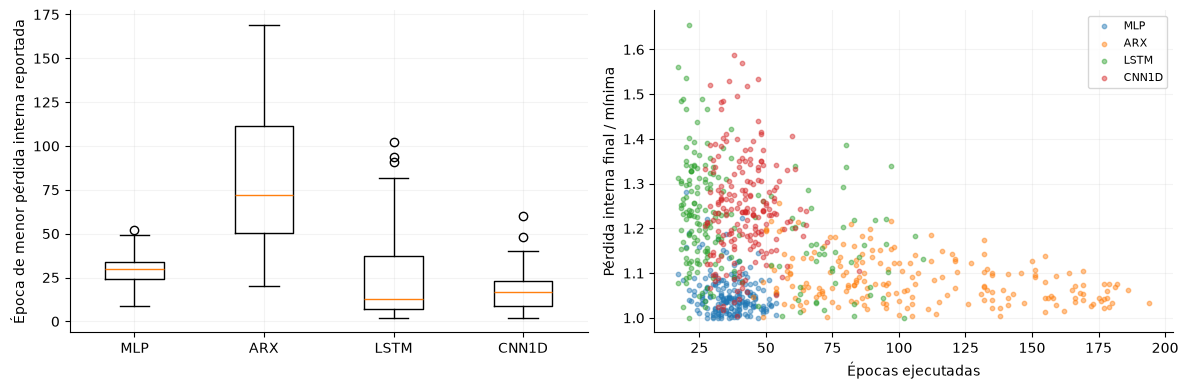

In [8]:
final_hist=ajustes.loc[ajustes.etapa=='final'].copy()
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].boxplot([runs.loc[runs.modelo==n,'mejor_epoca'] for n in modelos],tick_labels=[etiquetas[n] for n in modelos])
axes[0].set_ylabel('Época de menor pérdida interna reportada')
for nombre in modelos:
    d=final_hist[final_hist.modelo==nombre]
    # Las pérdidas sólo son comparables dentro de una misma función y escala.
    cociente=d.perdida_validacion_final/d.perdida_validacion_minima
    axes[1].scatter(d.epocas,cociente,label=etiquetas[nombre],s=10,alpha=.45)
axes[1].set(xlabel='Épocas ejecutadas',ylabel='Pérdida interna final / mínima'); axes[1].legend(fontsize=8)
fig.tight_layout(); display(fig); plt.close(fig)
tope=int((runs.epocas>=200).sum())


0 ajustes finales alcanzan el máximo de 200 épocas. Un cociente mayor que uno indica que el último estado no coincide con el mínimo de pérdida; el pipeline restaura el estado seleccionado por parada temprana. No se comparan directamente pérdidas MAE, Huber y MSE entre familias ni se presentan estos resúmenes como curvas de aprendizaje.

## 10.8 Comparaciones pareadas entre inicializaciones

El análisis secundario se fija en plan_analisis_secundario.json después de la publicación de los resultados; no es un preregistro anterior al entrenamiento. Las semillas 1000–1194 se aparean entre familias. Se estiman diferencias medias e intervalos bootstrap por semillas, t pareada y Wilcoxon bilateral como sensibilidad; Holm se aplica a tres contrastes neuronales y, por separado, a tres comparaciones con ARX.

La unidad de este análisis es la inicialización sobre una prueba fija, distinta del origen diario del pronóstico. Los contrastes cuantifican variabilidad algorítmica condicionada a 2022–2025; no demuestran superioridad temporal en días no observados. Shapiro–Wilk y Q–Q describen las diferencias. La t se interpreta como aproximación de la media con 195 pares y se contrasta con intervalos bootstrap; Wilcoxon es sensibilidad de rangos y no equivale a un contraste de medias cuando hay asimetría.

,Familia,A,B,Delta_B_menos_A,IC95_inf,IC95_sup,Reduccion_A_pct,IC95_reduccion_inf,IC95_reduccion_sup,Cohen_dz,t_p,t_Holm,Wilcoxon_p,Wilcoxon_Holm,Shapiro_p
0,Neuronales,mlp,lstm,1.0558,0.9808,1.1260,60.3907,58.6030,61.9318,2.0396,3.19e-71,6.37e-71,9.48e-34,2.84e-33,5.69e-19
1,Neuronales,mlp,cnn1d,1.3776,1.3679,1.3867,66.5479,66.2674,66.8089,20.5836,4.16e-257,1.25e-256,9.48e-34,2.84e-33,0.000389
2,Neuronales,lstm,cnn1d,0.3218,0.2512,0.3951,15.5447,12.1402,19.0799,0.6161,2.61e-15,2.61e-15,6.4e-11,6.4e-11,1.53e-18
3,Contexto ARX,mlp,arx_lineal,0.1388,0.1298,0.1479,16.6968,15.7395,17.6643,2.1651,2.47e-75,4.93e-75,9.48e-34,2.84e-33,0.00487
4,Contexto ARX,lstm,arx_lineal,-0.9170,-0.9885,-0.8433,-110.3123,-119.2373,-101.2699,-1.7660,1.05e-61,1.05e-61,5.06e-33,5.06e-33,1.81e-18
5,Contexto ARX,cnn1d,arx_lineal,-1.2388,-1.2495,-1.2281,-149.0220,-151.4478,-146.6388,-16.0846,2.17e-236,6.51e-236,9.48e-34,2.84e-33,0.381


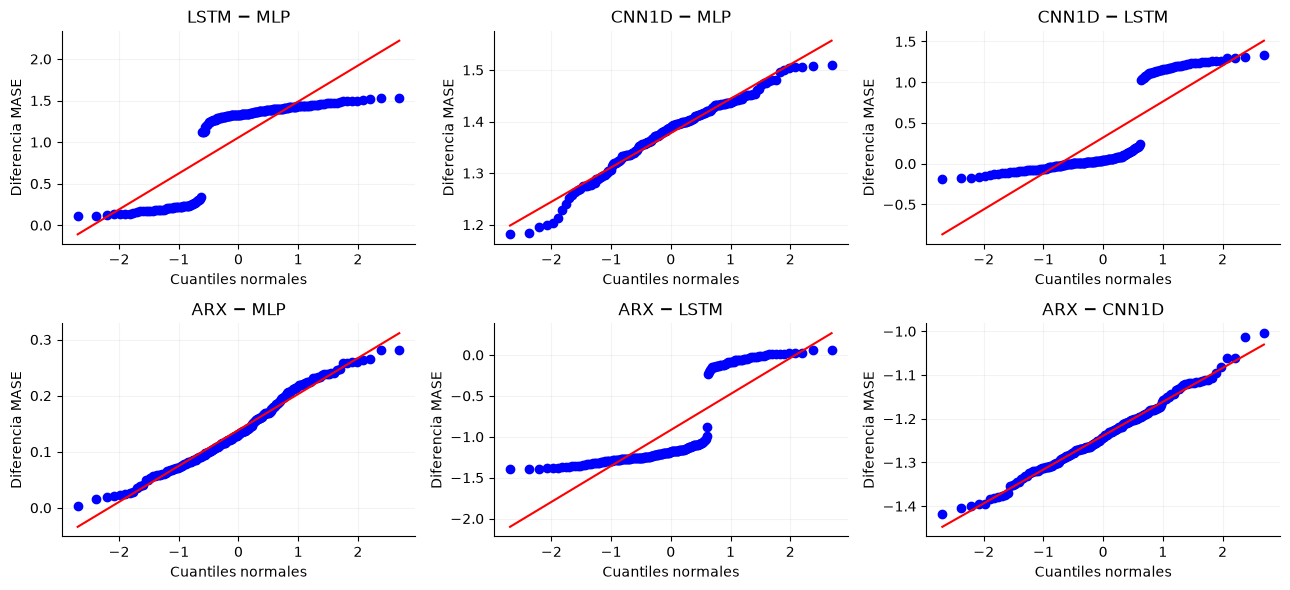

In [9]:
rng=np.random.default_rng(analisis['semilla_analisis'])
B=analisis['bootstrap_replicas']; pares=[]
familias={'Neuronales':list(itertools.combinations(neuronales,2)),
          'Contexto ARX':[(n,'arx_lineal') for n in neuronales]}
qq=[]
for familia,comparaciones in familias.items():
    for a,b in comparaciones:
        va=matriz[a].to_numpy(); vb=matriz[b].to_numpy(); d=vb-va
        n=len(d); sd=float(d.std(ddof=1)); indices=rng.integers(0,n,size=(B,n))
        delta_boot=d[indices].mean(axis=1)
        mejora_boot=100*(1-va[indices].mean(axis=1)/vb[indices].mean(axis=1))
        ci=np.quantile(delta_boot,[.025,.975]); ci_rel=np.quantile(mejora_boot,[.025,.975])
        t=stats.ttest_rel(vb,va)
        w=stats.wilcoxon(np.round(d,12),alternative='two-sided',method='asymptotic')
        sh=stats.shapiro(d)
        rangos=stats.rankdata(np.abs(d)); rb=float(np.sum(np.sign(d)*rangos)/rangos.sum())
        pares.append({'Familia':familia,'A':a,'B':b,'Delta_B_menos_A':d.mean(),
            'IC95_inf':ci[0],'IC95_sup':ci[1],'Reduccion_A_pct':100*(1-va.mean()/vb.mean()),
            'IC95_reduccion_inf':ci_rel[0],'IC95_reduccion_sup':ci_rel[1],
            'Cohen_dz':d.mean()/sd,'Rango_biserial':rb,'Victorias_A_pct':100*np.mean(d>0),
            't_p':float(t.pvalue),'Wilcoxon_p':float(w.pvalue),'Shapiro_p':float(sh.pvalue),
            'Asimetria_diferencias':float(stats.skew(d,bias=False))})
        qq.append((a,b,d))
contrastes=pd.DataFrame(pares)
for familia,idx in contrastes.groupby('Familia').groups.items():
    for prueba in ['t','Wilcoxon']:
        contrastes.loc[idx,prueba+'_Holm']=multipletests(contrastes.loc[idx,prueba+'_p'],method='holm')[1]
display(contrastes[['Familia','A','B','Delta_B_menos_A','IC95_inf','IC95_sup','Reduccion_A_pct',
    'IC95_reduccion_inf','IC95_reduccion_sup','Cohen_dz','t_p','t_Holm','Wilcoxon_p','Wilcoxon_Holm','Shapiro_p']].style.format(precision=4,
    formatter={k:'{:.3g}' for k in ['t_p','t_Holm','Wilcoxon_p','Wilcoxon_Holm','Shapiro_p']}))
contrastes.to_csv(OUT/'contrastes_semillas.csv',index=False)
fig,axes=plt.subplots(2,3,figsize=(13,6))
for ax,(a,b,d) in zip(axes.ravel(),qq):
    stats.probplot(d,dist='norm',plot=ax)
    ax.set(title=etiquetas[b]+' − '+etiquetas[a],xlabel='Cuantiles normales',ylabel='Diferencia MASE')
fig.tight_layout(); display(fig); plt.close(fig)
principal=contrastes[contrastes.Familia=='Neuronales']
n_rechazos=int((principal.t_Holm<.05).sum())
peor_shapiro=float(principal.Shapiro_p.min())


Los 3 contrastes de medias entre redes rechazan igualdad tras Holm en este análisis por semillas. Los Q–Q permiten reconocer colas y asimetría que la tabla no resume; el menor p de Shapiro–Wilk es 5.69e-19. Los intervalos y tamaños de efecto corresponden a inicializaciones sobre los mismos días, sin una conclusión confirmatoria sobre generalización temporal.

## 10.9 Rangos y descomposición de variabilidad

Friedman se calcula sobre las tres redes con semillas apareadas. Su p se calibra mediante 19.999 permutaciones de etiquetas dentro de cada semilla para evitar depender exclusivamente de la aproximación asintótica con tres métodos. Nemenyi se presenta como post-hoc aproximado de rangos. La descomposición de sumas de cuadrados separa diferencias entre familias, efecto común de semilla e interacción; no representa una estimación de ruido irreducible.

Out[0]: 330


,A,B,Diferencia_rango,p_Nemenyi_aprox
0,MLP,LSTM,1.287179,<1e-15
1,MLP,CNN1D,1.712821,<1e-15
2,LSTM,CNN1D,0.425641,7.82e-05


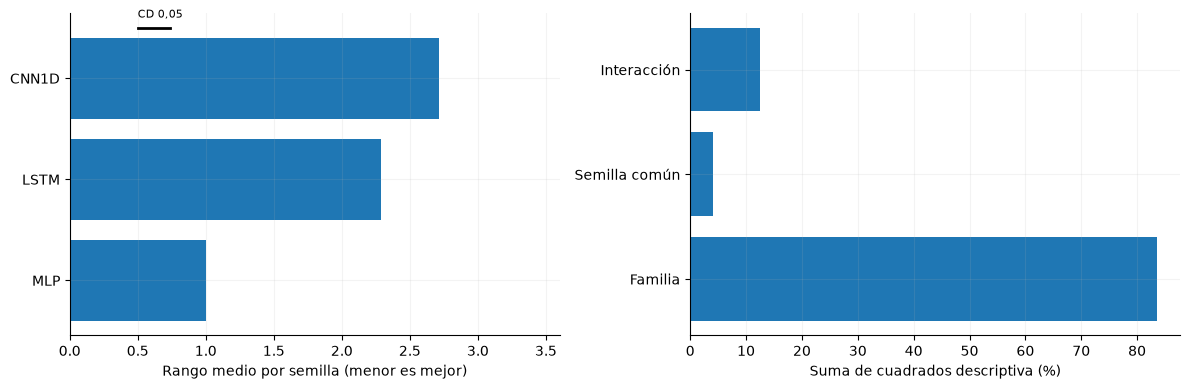

In [10]:
v=matriz[neuronales].to_numpy(); n,k=v.shape
rangos=stats.rankdata(v,axis=1); rangos_medios=rangos.mean(axis=0)
friedman=stats.friedmanchisquare(*[v[:,j] for j in range(k)])
q_sin_corr=12*n/(k*(k+1))*np.sum((rangos_medios-(k+1)/2)**2)
correccion=q_sin_corr/friedman.statistic if friedman.statistic>0 else 1.
rng=np.random.default_rng(11037); excedencias=0; Bf=analisis['permutaciones_friedman']
for inicio in range(0,Bf,1000):
    m=min(1000,Bf-inicio)
    perm=np.argsort(rng.random((m,n,k)),axis=2)
    rp=np.take_along_axis(np.broadcast_to(rangos,(m,n,k)),perm,axis=2).mean(axis=1)
    qp=12*n/(k*(k+1))*np.sum((rp-(k+1)/2)**2,axis=1)/correccion
    excedencias+=int(np.sum(qp>=friedman.statistic-1e-12))
p_perm=(excedencias+1)/(Bf+1)
se_rangos=np.sqrt(k*(k+1)/(6*n))
cd=float(stats.studentized_range.ppf(.95,k,np.inf)/np.sqrt(2)*se_rangos)
nemenyi=[]
for i,j in itertools.combinations(range(k),2):
    q=abs(rangos_medios[i]-rangos_medios[j])/se_rangos*np.sqrt(2)
    nemenyi.append({'A':etiquetas[neuronales[i]],'B':etiquetas[neuronales[j]],
        'Diferencia_rango':abs(rangos_medios[i]-rangos_medios[j]),
        'p_Nemenyi_aprox':float(stats.studentized_range.sf(q,k,np.inf))})
display(pd.DataFrame(nemenyi).style.format({'p_Nemenyi_aprox':lambda p:'<1e-15' if p<1e-15 else f'{p:.3g}'}))
x=matriz.to_numpy(); total=x.mean(); medias_modelo=x.mean(axis=0); medias_semilla=x.mean(axis=1)
ss_modelo=len(x)*np.sum((medias_modelo-total)**2)
ss_semilla=x.shape[1]*np.sum((medias_semilla-total)**2)
ss_interaccion=np.sum((x-medias_modelo[None,:]-medias_semilla[:,None]+total)**2)
ss=np.array([ss_modelo,ss_semilla,ss_interaccion]); fracciones=100*ss/ss.sum()
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].barh([etiquetas[a] for a in neuronales],rangos_medios)
axes[0].set(xlabel='Rango medio por semilla (menor es mejor)',xlim=(0,3.6))
axes[0].plot([.5,.5+cd],[2.5,2.5],color='black',lw=2); axes[0].text(.5,2.6,'CD 0,05',fontsize=8)
axes[1].barh(['Familia','Semilla común','Interacción'],fracciones); axes[1].set_xlabel('Suma de cuadrados descriptiva (%)')
fig.tight_layout(); display(fig); plt.close(fig)
salida_rangos={'friedman_Q':float(friedman.statistic),'p_permutacion':float(p_perm),
    'replicas':Bf,'rangos':dict(zip(neuronales,map(float,rangos_medios))),
    'diferencia_critica':cd,'varianza_descriptiva_pct':list(map(float,fracciones))}
(OUT/'rangos_variabilidad.json').write_text(json.dumps(salida_rangos,indent=2),encoding='utf-8')


Friedman obtiene Q = 310.16 y p de permutación 0.00005, con resolución limitada por 19999 réplicas. La diferencia crítica aproximada es 0.237 rangos. Las diferencias entre familias explican el 83.5 % de la suma de cuadrados del cuadro de resultados. Estas semillas no representan bases de datos independientes; la lectura de rangos permanece condicionada a la prueba compartida.

## 10.10 Dimensionamiento pareado y relevancia práctica

Se utiliza el piloto, no las diferencias finales, para estimar la desviación de diferencias entre semillas coincidentes. El cálculo retrospectivo aplica la aproximación normal pareada de la pauta, un margen del 3 % del MASE piloto del comparador y un nivel conservador Bonferroni por familia. Se reporta la diferencia mínima detectable con 195 semillas; no se modifica el tamaño de las ejecuciones ya terminadas.

In [11]:
pil=piloto.pivot(index='semilla',columns='modelo',values='MASE')
dim=[]
for familia,comparaciones in familias.items():
    m=len(comparaciones); z=stats.norm.ppf(1-.05/(2*m))+stats.norm.ppf(.8)
    for a,b in comparaciones:
        dif=(pil[b]-pil[a]).dropna(); sd=float(dif.std(ddof=1))
        delta=.03*float(pil[b].mean()); R_pareado=max(1,int(np.ceil((z*sd/delta)**2)))
        mde=z*sd/np.sqrt(n_final)
        dim.append({'Familia':familia,'A':a,'B':b,'n_piloto_pares':len(dif),
            'DE_diferencias':sd,'delta_MASE':delta,'delta_sobre_DE':delta/sd,
            'n_estimado_pareado':R_pareado,'MDE_con_195':mde,
            'MDE_relativa_pct':100*mde/pil[b].mean(),'MDE_supera_delta':bool(mde>delta)})
dimensionamiento=pd.DataFrame(dim)
display(dimensionamiento.style.format(precision=4))
dimensionamiento.to_csv(OUT/'dimensionamiento_pareado.csv',index=False)
limite_mde=float(dimensionamiento.loc[dimensionamiento.Familia=='Neuronales','MDE_relativa_pct'].max())


,Familia,A,B,n_piloto_pares,DE_diferencias,delta_MASE,delta_sobre_DE,n_estimado_pareado,MDE_con_195,MDE_relativa_pct,MDE_supera_delta
0,Neuronales,mlp,lstm,5,0.1613,0.0454,0.2815,133,0.0374,2.4691,False
1,Neuronales,mlp,cnn1d,5,0.0407,0.0481,1.1812,8,0.0094,0.5885,False
2,Neuronales,lstm,cnn1d,5,0.1412,0.0481,0.3408,91,0.0327,2.0396,False
3,Contexto ARX,mlp,arx_lineal,5,0.0167,0.0188,1.1277,9,0.0039,0.6164,False
4,Contexto ARX,lstm,arx_lineal,5,0.1586,0.0188,0.1188,743,0.0367,5.8521,True
5,Contexto ARX,cnn1d,arx_lineal,5,0.0339,0.0188,0.5550,34,0.0079,1.2525,False


La mayor diferencia mínima detectable estimada entre redes es 2.47 % bajo los supuestos pareados y la dispersión de sólo cinco semillas piloto. En estos contrastes neuronales, el máximo es inferior al margen del 3 % bajo la aproximación utilizada. El valor es una aproximación de diseño, no potencia temporal ni evidencia de equivalencia.

## 10.11 Evidencia experimental y alcance

| Requisito del E1 | Evidencia incorporada | Alcance |
|---|---|---|
| Tres modelos de Deep Learning | MLP, LSTM y CNN1D; ecuaciones, capacidad y configuraciones | ARX se presenta como contexto. La revisión sistemática de frecuencias sigue pendiente. |
| Pipeline completo | Fuentes de ventanas, escalado, entrenamiento, búsqueda, piloto y prueba | Código íntegro en el apéndice; no se repiten entrenamientos. |
| Piloto y múltiples ejecuciones | Cinco semillas piloto y 195 finales por familia | Dimensionamiento original y cálculo pareado retrospectivo documentados. |
| Presupuesto comparable | Espacios, tiempos y número de ajustes | LSTM evaluó cinco candidatos frente a veinte: limitación de equidad. |
| Métricas, ranking y baseline | MASE, MAE, RMSE, sMAPE, R² y referencias deterministas | Intervalos por inicialización y por días se reportan separadamente. |
| Curvas y estabilidad | Historiales completos, pérdidas y épocas | Ejemplos con semilla 1000 fijada de antemano; todos los historiales se conservan. |
| Errores por horizonte y segmentos | Las 24 horas, años, tipos de día y cuartiles descriptivos | Análisis posterior a congelar configuraciones. |
| Inferencia y residuos | Bootstrap temporal, DM–HLN, Holm, Ljung–Box, ARCH y BDS | Análisis secundario retrospectivo, sin equivalencia con evaluación prospectiva. |
| Complejidad y costo | Parámetros, tiempos de ajuste, hardware, pesos y escaladores | La latencia de inferencia no se registró y no se deduce del tiempo de ajuste. |

El [análisis temporal completo](10_evaluacion.ipynb) verifica las predicciones, incorpora las curvas y desarrolla los diagnósticos. Las fuentes y la prueba son retrospectivas; la versión 2 se diseñó después de consultar la versión 1, conforme a las adendas. Los contrastes secundarios no corrigen esa limitación.

## 10.12 Código y reproducción

El [apéndice del pipeline](10_pipeline.md) contiene el código completo de ventanas, partición, escalado, arquitecturas, pérdidas, optimizador, parada temprana, búsqueda, piloto y prueba, extraído de la instantánea verificada. El capítulo muestra además todo el código utilizado para reconstruir tablas, gráficos y contrastes.

Los resultados se conservan en results/repositorio/02ff447d94fa78e1cde323fa2382da5bce24fb6e/results/base_v2. El registro IMPORTACION.json identifica la revisión descargada y sus archivos; el plan del análisis secundario y las tablas derivadas están en results/jbook/modelos. La importación no modifica las fuentes activas de entrenamiento.

Fundamento de rangos: [Demšar (2006)](https://jmlr.org/papers/v7/demsar06a.html). Las condiciones de [Wilcoxon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html) se consideran para interpretar asimetrías. La permutación calibra el estadístico de [Friedman](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.friedmanchisquare.html) con tres redes.